# Baseline Training Curves

Read `trainning_log.txt` and plot training and validation metrics by epoch. These are **training/validation results**, not test results. Change `LOG_PATH` to analyze another log.


In [1]:
from pathlib import Path
import re
import pandas as pd
import matplotlib.pyplot as plt

LOG_PATH = Path('trainning_log.txt')
if not LOG_PATH.is_file():
    raise FileNotFoundError('Run this notebook from the ViSpeech directory or update LOG_PATH.')
pattern = re.compile(
    r'EPOCH\s+(\d+)\s*\|\s*Train Loss:\s*([\d.eE+-]+)\s*\|\s*'
    r'Train Acc:\s*([\d.eE+-]+)\s*\|\s*Val Loss:\s*([\d.eE+-]+)\s*\|\s*'
    r'Val Acc:\s*([\d.eE+-]+)')
rows = [(int(m[0]), *map(float, m[1:]))
        for m in pattern.findall(LOG_PATH.read_text(encoding='utf-8', errors='replace'))]
if not rows:
    raise ValueError('No matching epoch records found in the log.')
history = pd.DataFrame(rows, columns=['epoch', 'train_loss', 'train_acc', 'val_loss', 'val_acc'])
if history['epoch'].duplicated().any():
    raise ValueError('Duplicate epochs found. Select a log from a single training run.')
history = history.sort_values('epoch').reset_index(drop=True)
best = history.loc[history['val_acc'].idxmax()]
best_loss = history.loc[history['val_loss'].idxmin()]
print(f'Log: {LOG_PATH.resolve()}')
print(f'Number of epochs: {len(history)}')
print(f"Best validation accuracy: {best.val_acc:.2%}, epoch {int(best.epoch)}")
print(f"Lowest validation loss: {best_loss.val_loss:.4f}, epoch {int(best_loss.epoch)}")
display(history.tail())


Log: C:\Users\Uyen\Documents\Master\LuanVan01\Code\ViSpeech\trainning_log.txt
Number of epochs: 300
Best validation accuracy: 91.67%, epoch 273
Lowest validation loss: 0.3089, epoch 248


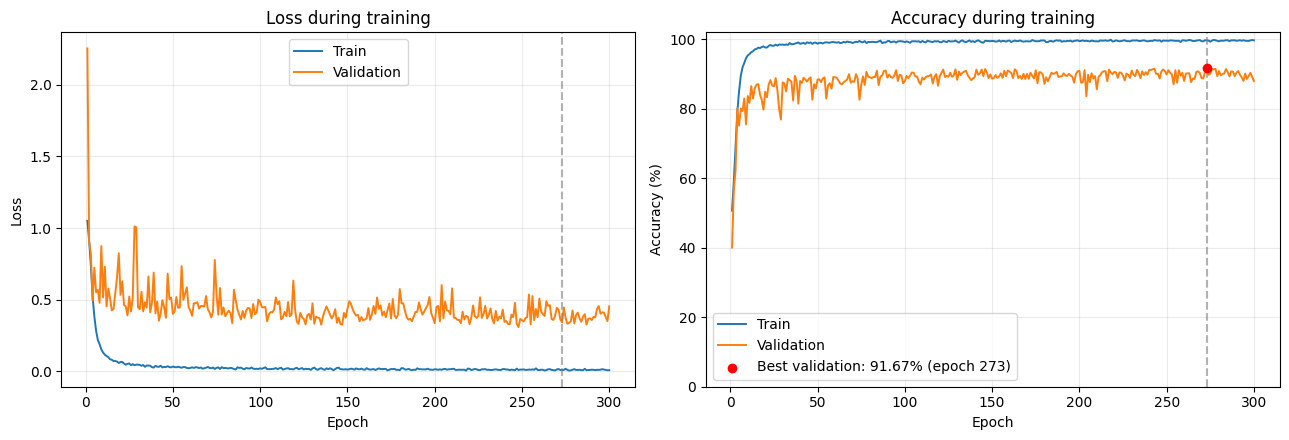

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(history.epoch, history.train_loss, label='Train', linewidth=1.4)
axes[0].plot(history.epoch, history.val_loss, label='Validation', linewidth=1.4)
axes[0].set(title='Loss during training', xlabel='Epoch', ylabel='Loss')
axes[1].plot(history.epoch, history.train_acc * 100, label='Train', linewidth=1.4)
axes[1].plot(history.epoch, history.val_acc * 100, label='Validation', linewidth=1.4)
axes[1].scatter([best.epoch], [best.val_acc * 100], color='red', zorder=5,
                label=f'Best validation: {best.val_acc:.2%} (epoch {int(best.epoch)})')
axes[1].set(title='Accuracy during training', xlabel='Epoch', ylabel='Accuracy (%)', ylim=(0, 102))
for ax in axes:
    ax.axvline(best.epoch, color='gray', linestyle='--', alpha=0.6)
    ax.grid(alpha=0.25)
    ax.legend()
fig.tight_layout()
OUTPUT_DIR = Path('training_plots')
OUTPUT_DIR.mkdir(exist_ok=True)
fig.savefig(OUTPUT_DIR / 'training_curves.png', dpi=200, bbox_inches='tight')
plt.show()
plt.close(fig)


## How to Read the Plots

- Lower loss and higher accuracy indicate a better fit on the corresponding dataset.
- If training improves while validation stops improving or gets worse, this may indicate overfitting.
- The dashed line marks the epoch with the highest validation accuracy, matching the checkpoint selection criterion in `train.py`.
- The plots show raw per-epoch values without smoothing. Assess generalization using test results as well.
